# 02 - Training Model Deteksi Promosi Judi Online

Melatih dan membandingkan 5 algoritma klasik untuk klasifikasi teks komentar YouTube:
**Naive Bayes, SVM, Random Forest, KNN, Logistic Regression**, ditambah **voting mayoritas** dari kelimanya
(cara yang dipakai worker pada sistem lama).

Alur:
1. Setup & load dataset Kaggle
2. Cleaning (fungsi yang **sama** dengan notebook 01 - scraping)
3. Deduplikasi -> split train/test -> balancing data latih
4. Training + evaluasi tiap model (TF-IDF + classifier dalam satu `Pipeline`)
5. Perbandingan model (tabel, heatmap, confusion matrix, ROC, FP/FN)
6. Analisis kesalahan & kata paling berpengaruh
7. Eksperimen: seberapa bersih teks sebaiknya? (uji ketahanan terhadap penyamaran non-ASCII)
8. Simpan model + informasi training (`models/`)

### Perbedaan dengan notebook lama (`Gambling_Trainer_kagle.ipynb`)
| Lama | Sekarang | Alasan |
|---|---|---|
| Training memakai `komentar_clean` buatan pembuat dataset | Cleaning ulang dari `komentar` dengan `clean_text` | cleaning saat training **harus sama** dengan saat prediksi data scraping |
| Tidak ada normalisasi Unicode | NFKC + homoglif + gabung huruf yang dispasi | huruf "fancy", Cyrillic, & `P L U T O 8 8` adalah trik utama spam judi |
| Simbol non-ASCII dibuang begitu saja | Triknya dicatat sebagai **token sinyal** (`xxfancy`, `xxhomoglyph`, `xxspaced`, `xxdecor`) | penyamaran itu sendiri adalah ciri promosi judi - jangan sampai hilang |
| TF-IDF di-fit ke seluruh data **sebelum** split | TF-IDF di dalam `Pipeline`, hanya belajar dari data latih | mencegah kebocoran informasi data uji |
| Undersampling seluruh data lalu split | Split dulu, undersampling **hanya data latih** | data uji mencerminkan distribusi asli |
| Duplikat template tidak dihapus | Deduplikasi sebelum split | kalimat yang sama tidak boleh ada di latih & uji sekaligus |
| Nilai FP/FN di grafik diketik manual | Dihitung dari confusion matrix | |
| Vectorizer & model disimpan terpisah | Satu file `Pipeline` per model | tidak mungkin salah pasang vectorizer |

## 1. Setup & load data

In [1]:
%pip install -q kagglehub emoji nltk

/home/drpoch/Devapp/claude/Tesis/tugas/NLP-AdvanceAI/Online-Gamblig-Skripsie/.venv/bin/python: No module named pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import glob
import json
import os
import platform
import shutil
import time
from datetime import datetime

import joblib
import numpy as np
import pandas as pd
import kagglehub
import sklearn
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

RANDOM_STATE = 42
OUTPUT_DIR = "models"
pd.set_option("display.max_colwidth", 120)

import matplotlib.pyplot as plt
import seaborn as sns

# Palet konsisten di semua notebook: biru = komentar normal, oranye = promosi judi
WARNA_LABEL = {0: "#2a78d6", 1: "#eb6834"}
NAMA_LABEL = {0: "Normal (0)", 1: "Promosi judi (1)"}
WARNA_MODEL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titleweight": "bold",
})

/home/drpoch/Devapp/claude/Tesis/tugas/NLP-AdvanceAI/Online-Gamblig-Skripsie/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
import re
import unicodedata

import emoji
import nltk
from nltk.corpus import stopwords

nltk.download("stopwords", quiet=True)
STOPWORDS_ID = set(stopwords.words("indonesian"))

# Emoji khusus YouTube berbentuk teks, mis. ":face-blue-smiling:" (menggantikan youtubeemoji.csv)
RE_YT_EMOJI = re.compile(r":[a-z0-9]+(?:-[a-z0-9]+)+:")
RE_URL = re.compile(r"https?://\S+|www\.\S+")
RE_MENTION_HASHTAG = re.compile(r"[@#]\w+")
RE_NON_ALNUM = re.compile(r"[^0-9a-z\s]")
# Huruf yang dispasi untuk mengelabui filter: "p l u t o 8 8" -> "pluto88"
RE_SPACED = re.compile(r"\b(?:\w ){3,}\w\b")  # minimal 4 karakter, agar "1 2 m" tidak ikut

# Homoglif: huruf Cyrillic/Yunani yang bentuknya sama dengan huruf Latin.
# NFKC TIDAK mengubahnya (Cyrillic "a" tetap Cyrillic), jadi dipetakan manual.
HOMOGLYPH = {
    "а": "a", "е": "e", "о": "o", "р": "p", "с": "c", "у": "y",
    "х": "x", "к": "k", "м": "m", "т": "t", "н": "h", "в": "b",
    "і": "i", "ј": "j", "ѕ": "s", "ԁ": "d",
    "α": "a", "ο": "o", "ε": "e", "ι": "i", "κ": "k", "ν": "v",
    "ρ": "p", "τ": "t", "υ": "u", "χ": "x",
}
TABEL_HOMOGLYPH = str.maketrans(HOMOGLYPH)

# Token penanda trik penyamaran. Ditambahkan ke teks supaya TF-IDF bisa memakainya sebagai fitur.
SINYAL = {
    "xxfancy": "huruf/angka gaya (bold, italic, fullwidth, circled) yang dinormalisasi NFKC",
    "xxhomoglyph": "huruf Cyrillic/Yunani yang menyamar di dalam kata Latin",
    "xxspaced": "huruf yang dipisah spasi, mis. 'P L U T O 8 8'",
    "xxdecor": "simbol dekoratif non-ASCII selain emoji, mis. blok/bintang/aksara asing",
}


def obfuscation_signals(text):
    # Mendeteksi trik penyamaran dari teks ASLI, sebelum informasinya hilang oleh cleaning
    sinyal = set()
    if not isinstance(text, str):
        return sinyal
    for c in text:
        if c.isascii() or c.isspace():
            continue
        n = unicodedata.normalize("NFKC", c)
        if n.isascii():
            if n.isalnum():
                sinyal.add("xxfancy")
        elif c.lower() in HOMOGLYPH:
            continue  # dicek per kata di bawah
        elif (emoji.is_emoji(c) or unicodedata.category(c) in ("Mn", "Me", "Cf", "Sk")
              or unicodedata.name(c, "").startswith("LATIN")):
            continue
        else:
            sinyal.add("xxdecor")
    for kata in unicodedata.normalize("NFKC", text).lower().split():
        if any(c in HOMOGLYPH for c in kata) and any("a" <= c <= "z" for c in kata):
            sinyal.add("xxhomoglyph")
    return sinyal


def clean_text(text, remove_stopwords=True, add_signals=True):
    # Pipeline cleaning yang SAMA untuk training dan untuk data hasil scraping
    if not isinstance(text, str):
        return ""
    sinyal = obfuscation_signals(text) if add_signals else set()  # 0. catat trik penyamaran
    text = unicodedata.normalize("NFKC", text)        # 1. huruf "fancy" (Mathematical Bold dsb.) -> ASCII biasa
    text = emoji.replace_emoji(text, replace=" ")     # 2. hapus emoji unicode (termasuk bendera)
    text = RE_YT_EMOJI.sub(" ", text)                 # 3. hapus emoji khusus YouTube
    text = text.lower().translate(TABEL_HOMOGLYPH)    # 4. huruf kecil + homoglif -> Latin
    text = "".join(c for c in unicodedata.normalize("NFKD", text)
                   if not unicodedata.combining(c))   #    hapus aksen: cafe' -> cafe
    text = RE_URL.sub(" ", text)                      # 5. hapus URL
    text = RE_MENTION_HASHTAG.sub(" ", text)          # 6. hapus mention & hashtag
    text = RE_NON_ALNUM.sub(" ", text)                # 7. hapus tanda baca / simbol
    text = re.sub(r"\s+", " ", text).strip()          # 8. normalisasi spasi
    digabung = RE_SPACED.sub(lambda m: m.group().replace(" ", ""), text)  # 9. gabung huruf yang dispasi
    if add_signals and digabung != text:
        sinyal.add("xxspaced")
    tokens = digabung.split()
    if remove_stopwords:                              # 10. hapus stopword Bahasa Indonesia
        tokens = [t for t in tokens if t not in STOPWORDS_ID]
    return " ".join(tokens + sorted(sinyal))          # 11. tempel token sinyal di akhir

In [4]:
path = kagglehub.dataset_download("yaemico/judionline")
csv_file = glob.glob(os.path.join(path, "*.csv"))[0]
df = pd.read_csv(csv_file)
print(df.shape)
df[["komentar", "label"]].head()

(10230, 9)


,komentar,label
0,Makin yakin abis baca review lain tentang ✌✌𝐒𝐆𝐈𝟖𝟖.,1
1,Paling suka model H2 😍🔥,0
2,Mobilnya udah hancur 🥺,0
3,░𝙈𝘼𝙉𝙐𝙏88░benar2 bikin aku jadi sultan,1
4,Semoga lekas recover mobilnya mas Dipo,0


## 2. Cleaning

Contoh tiap langkah `clean_text` (penjelasan detail ada di notebook 01):

In [5]:
df["text_clean"] = df["komentar"].apply(clean_text)                       # dipakai model utama
df["text_plain"] = df["komentar"].apply(clean_text, add_signals=False)    # untuk eksperimen bagian 7

contoh = df[df["komentar"].str.len() > 30].groupby("label").sample(3, random_state=7)
for _, r in contoh.iterrows():
    print(f"[label {r['label']}]")
    print("  komentar       :", r["komentar"])
    print("  komentar_clean :", r["komentar_clean"], "  <- versi dataset")
    print("  text_clean     :", r["text_clean"], "  <- versi kita")

print()
print("Token sinyal penyamaran:")
for k, v in SINYAL.items():
    print(f"  {k:12s} {v}")

[label 0]
  komentar       :  @hanifalii23  saya cuma asal tag bang,kflgy
  komentar_clean : saya cuma asal tag bang , kflgy   <- versi dataset
  text_clean     : tag bang kflgy   <- versi kita
[label 0]
  komentar       : Entah lah bang, mau apa coba mereka menjabat 😅.
  komentar_clean : entah lah bang , mau apa coba mereka menjabat .   <- versi dataset
  text_clean     : bang coba menjabat   <- versi kita
[label 0]
  komentar       : Beli ini cuman buat telpon dan wa 😅
  komentar_clean : beli ini cuman buat telpon dan wa   <- versi dataset
  text_clean     : beli cuman telpon wa   <- versi kita
[label 1]
  komentar       : Gas tu gan mandalika77 zeusnya nya galak tu, lagi mau aja tu ngasi gw baru dikasi maxwin
  komentar_clean : gas tu gan mandalika77 zeusnya nya galak tu , aja tu ngasi gw dikasi maxwin   <- versi dataset
  text_clean     : gas tu gan mandalika77 zeusnya nya galak tu aja tu ngasi gw dikasi maxwin   <- versi kita
[label 1]
  komentar       : temen gue bilang alexis17 

## 3. Deduplikasi, split, dan balancing

In [6]:
n_awal = len(df)
data = df[df["text_clean"].str.len() > 0]
n_tidak_kosong = len(data)

# Jika teks yang sama punya label berbeda, ambil label mayoritas
data = (data.groupby("text_clean", as_index=False)
            .agg(label=("label", lambda s: int(s.mean() >= 0.5)),
                 text_plain=("text_plain", "first"), komentar=("komentar", "first")))

print(f"Data awal             : {n_awal:,}")
print(f"Setelah buang kosong  : {n_tidak_kosong:,}")
print(f"Setelah deduplikasi   : {len(data):,}  (dibuang {n_tidak_kosong - len(data):,} duplikat)")
print()
print(data["label"].value_counts().rename(NAMA_LABEL))

Data awal             : 10,230
Setelah buang kosong  : 10,211
Setelah deduplikasi   : 8,624  (dibuang 1,587 duplikat)

label
Normal (0)          5929
Promosi judi (1)    2695
Name: count, dtype: int64


In [7]:
X_train_full, X_test, y_train_full, y_test = train_test_split(
    data["text_clean"], data["label"], test_size=0.2, stratify=data["label"], random_state=RANDOM_STATE)

# Undersampling kelas mayoritas HANYA pada data latih
train = pd.DataFrame({"text": X_train_full, "label": y_train_full})
n_min = train["label"].value_counts().min()
train_bal = (train.groupby("label").sample(n=n_min, random_state=RANDOM_STATE)
                  .sample(frac=1, random_state=RANDOM_STATE))
X_train, y_train = train_bal["text"], train_bal["label"]

ringkas_split = pd.DataFrame({
    "train (sebelum balancing)": y_train_full.value_counts(),
    "train (setelah balancing)": y_train.value_counts(),
    "test": y_test.value_counts(),
}).rename(index=NAMA_LABEL)
ringkas_split.loc["Total"] = ringkas_split.sum()
ringkas_split

,train (sebelum balancing),train (setelah balancing),test
label,,,
Normal (0),4743,2156,1186
Promosi judi (1),2156,2156,539
Total,6899,4312,1725


## 4. Training & evaluasi

Setiap model adalah `Pipeline(TF-IDF -> classifier)`. Untuk tiap model dicatat:
- **CV F1 (5-fold)** pada data latih - seberapa stabil model
- **Accuracy, Precision, Recall, F1, ROC-AUC** pada data uji (kelas positif = promosi judi)
- waktu training

Random Forest memakai `GridSearchCV` seperti notebook lama. SVM dibungkus `CalibratedClassifierCV` untuk mendapatkan probabilitas
(`SVC(probability=True)` sudah deprecated di scikit-learn terbaru).

In [8]:
def tfidf():
    return TfidfVectorizer(max_features=5000)

MODELS = {
    "Naive Bayes": Pipeline([("tfidf", tfidf()), ("clf", MultinomialNB())]),
    "SVM": Pipeline([("tfidf", tfidf()), ("clf", CalibratedClassifierCV(SVC(random_state=RANDOM_STATE), ensemble=False))]),
    "Random Forest": GridSearchCV(
        Pipeline([("tfidf", tfidf()), ("clf", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))]),
        param_grid={"clf__n_estimators": [100, 200], "clf__max_depth": [10, None], "clf__min_samples_split": [2, 5]},
        cv=3, scoring="f1", n_jobs=-1),
    "KNN": Pipeline([("tfidf", tfidf()), ("clf", KNeighborsClassifier())]),
    "Logistic Regression": Pipeline([("tfidf", tfidf()), ("clf", LogisticRegression(max_iter=1000))]),
}

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
fitted, hasil, prediksi = {}, {}, {}

for nama, model in MODELS.items():
    t0 = time.time()
    model.fit(X_train, y_train)
    waktu = time.time() - t0

    if isinstance(model, GridSearchCV):
        print(f"[{nama}] parameter terbaik: {model.best_params_}")
        model = model.best_estimator_
    cv_f1 = cross_val_score(clone(model), X_train, y_train, cv=cv, scoring="f1", n_jobs=-1)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    fitted[nama] = model
    prediksi[nama] = (y_pred, y_prob)
    hasil[nama] = {
        "CV F1 (mean)": cv_f1.mean(),
        "CV F1 (std)": cv_f1.std(),
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "Waktu training (s)": waktu,
    }
    print(f"[{nama}] selesai dalam {waktu:.1f}s - F1 uji {hasil[nama]['F1']:.4f}")
    print(classification_report(y_test, y_pred, target_names=["normal", "judi"], digits=4))

[Naive Bayes] selesai dalam 0.0s - F1 uji 0.8650
              precision    recall  f1-score   support

      normal     0.9961    0.8626    0.9245      1186
        judi     0.7665    0.9926    0.8650       539

    accuracy                         0.9032      1725
   macro avg     0.8813    0.9276    0.8948      1725
weighted avg     0.9244    0.9032    0.9059      1725



[SVM] selesai dalam 4.8s - F1 uji 0.9608
              precision    recall  f1-score   support

      normal     0.9897    0.9739    0.9817      1186
        judi     0.9444    0.9777    0.9608       539

    accuracy                         0.9751      1725
   macro avg     0.9671    0.9758    0.9713      1725
weighted avg     0.9756    0.9751    0.9752      1725



[Random Forest] parameter terbaik: {'clf__max_depth': None, 'clf__min_samples_split': 5, 'clf__n_estimators': 100}


[Random Forest] selesai dalam 5.9s - F1 uji 0.9604
              precision    recall  f1-score   support

      normal     0.9847    0.9789    0.9818      1186
        judi     0.9542    0.9666    0.9604       539

    accuracy                         0.9751      1725
   macro avg     0.9695    0.9728    0.9711      1725
weighted avg     0.9752    0.9751    0.9751      1725



[KNN] selesai dalam 0.0s - F1 uji 0.5469
              precision    recall  f1-score   support

      normal     0.7801    0.9840    0.8702      1186
        judi     0.9170    0.3896    0.5469       539

    accuracy                         0.7983      1725
   macro avg     0.8486    0.6868    0.7086      1725
weighted avg     0.8229    0.7983    0.7692      1725



[Logistic Regression] selesai dalam 0.0s - F1 uji 0.9579
              precision    recall  f1-score   support

      normal     0.9774    0.9848    0.9811      1186
        judi     0.9660    0.9499    0.9579       539

    accuracy                         0.9739      1725
   macro avg     0.9717    0.9674    0.9695      1725
weighted avg     0.9739    0.9739    0.9739      1725



### Voting mayoritas

Worker lama menggabungkan kelima model dengan voting: komentar dianggap promosi jika **>= 3 dari 5** model memprediksi 1.

In [10]:
votes = np.vstack([prediksi[n][0] for n in fitted])
y_vote = (votes.mean(axis=0) >= 0.5).astype(int)
y_vote_prob = np.vstack([prediksi[n][1] for n in fitted]).mean(axis=0)
prediksi["Voting (5 model)"] = (y_vote, y_vote_prob)
hasil["Voting (5 model)"] = {
    "CV F1 (mean)": np.nan, "CV F1 (std)": np.nan,
    "Accuracy": accuracy_score(y_test, y_vote),
    "Precision": precision_score(y_test, y_vote),
    "Recall": recall_score(y_test, y_vote),
    "F1": f1_score(y_test, y_vote),
    "ROC-AUC": roc_auc_score(y_test, y_vote_prob),
    "Waktu training (s)": sum(h["Waktu training (s)"] for h in hasil.values()),
}
print(classification_report(y_test, y_vote, target_names=["normal", "judi"], digits=4))

              precision    recall  f1-score   support

      normal     0.9864    0.9815    0.9839      1186
        judi     0.9596    0.9703    0.9649       539

    accuracy                         0.9780      1725
   macro avg     0.9730    0.9759    0.9744      1725
weighted avg     0.9781    0.9780    0.9780      1725



## 5. Perbandingan model

In [11]:
metrics_df = pd.DataFrame(hasil).T.sort_values("F1", ascending=False)
metrics_df.style.format("{:.4f}").format("{:.1f}", subset=["Waktu training (s)"]).background_gradient(
    cmap="Blues", subset=["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"])

,CV F1 (mean),CV F1 (std),Accuracy,Precision,Recall,F1,ROC-AUC,Waktu training (s)
Voting (5 model),nan,nan,0.9780,0.9596,0.9703,0.9649,0.9971,10.8
SVM,0.9758,0.0024,0.9751,0.9444,0.9777,0.9608,0.9963,4.8
Random Forest,0.9741,0.0045,0.9751,0.9542,0.9666,0.9604,0.9950,5.9
Logistic Regression,0.9688,0.0022,0.9739,0.9660,0.9499,0.9579,0.9954,0.0
Naive Bayes,0.9294,0.0091,0.9032,0.7665,0.9926,0.8650,0.9943,0.0
KNN,0.9060,0.0086,0.7983,0.9170,0.3896,0.5469,0.8471,0.0


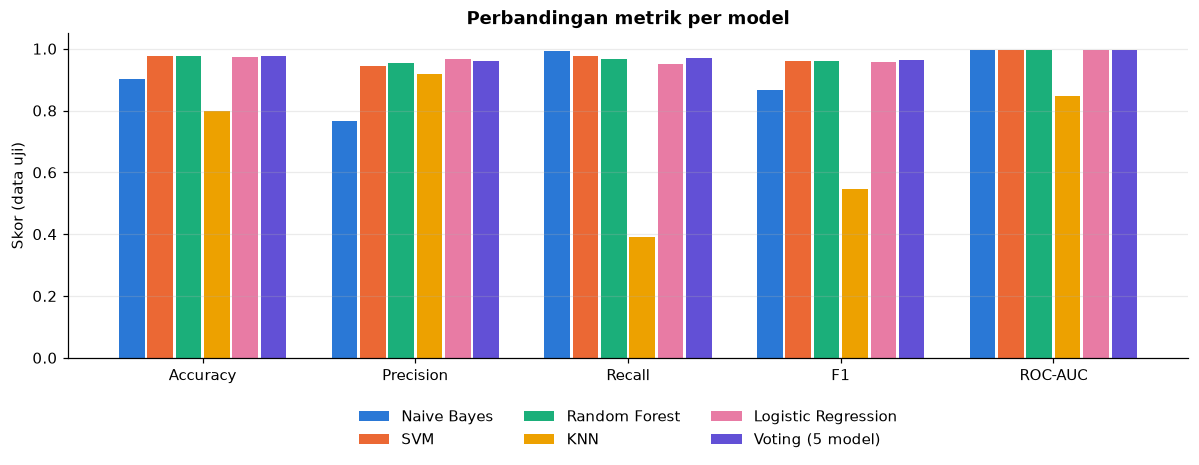

In [12]:
METRIK = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
urutan = list(hasil)  # urutan tetap -> warna tiap model selalu sama

fig, ax = plt.subplots(figsize=(11, 4.5))
lebar = 0.8 / len(urutan)
for i, nama in enumerate(urutan):
    x = np.arange(len(METRIK)) + i * lebar - 0.4 + lebar / 2
    ax.bar(x, [hasil[nama][m] for m in METRIK], width=lebar * 0.9, color=WARNA_MODEL[i], label=nama)
ax.set_xticks(np.arange(len(METRIK)), METRIK)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Skor (data uji)")
ax.set_title("Perbandingan metrik per model")
ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.32), frameon=False)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

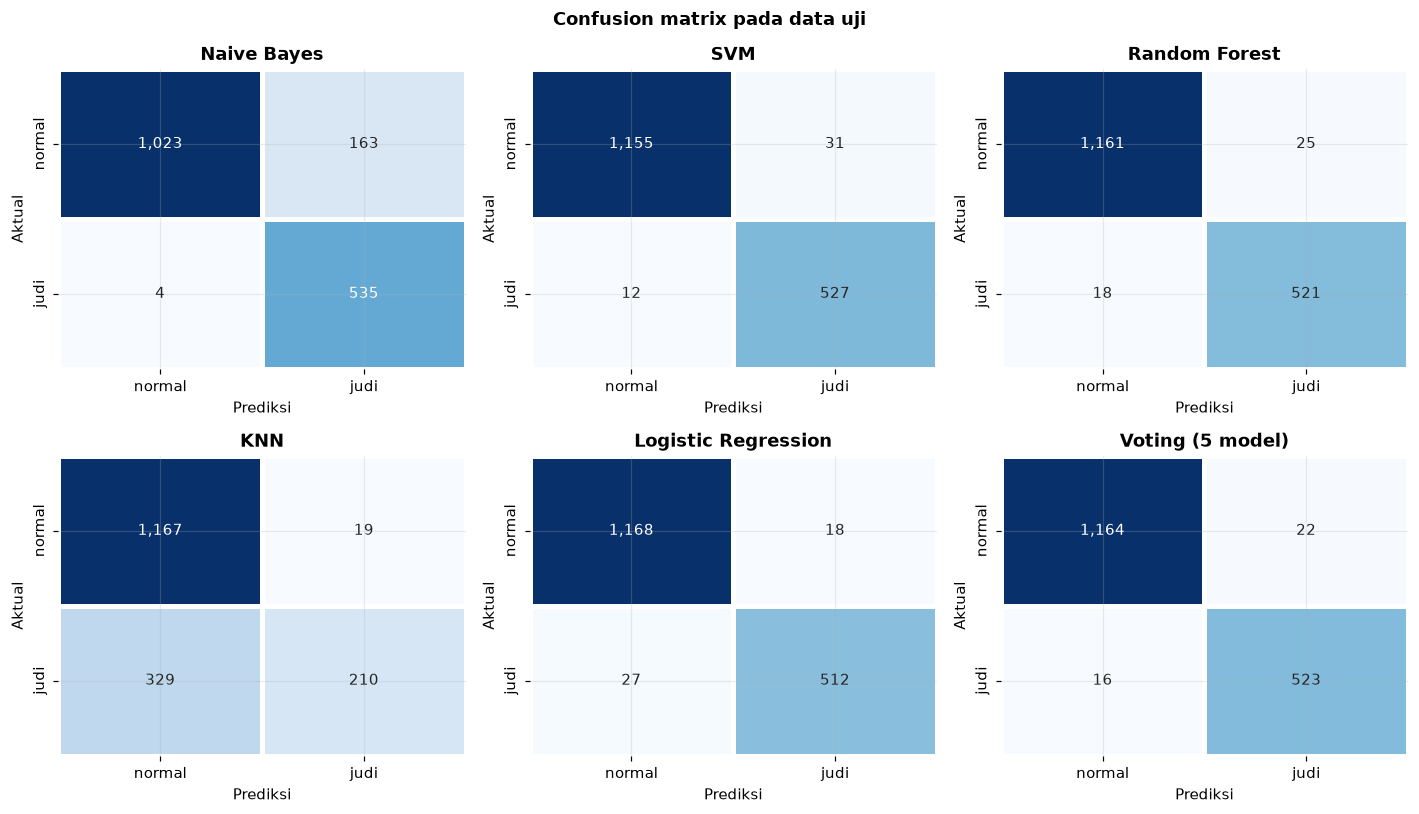

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7.5))
for ax, nama in zip(axes.ravel(), urutan):
    cm = confusion_matrix(y_test, prediksi[nama][0])
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax, linewidths=2, linecolor="white",
                xticklabels=["normal", "judi"], yticklabels=["normal", "judi"])
    ax.set_title(nama)
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Aktual")
plt.suptitle("Confusion matrix pada data uji", fontweight="bold")
plt.tight_layout()
plt.show()

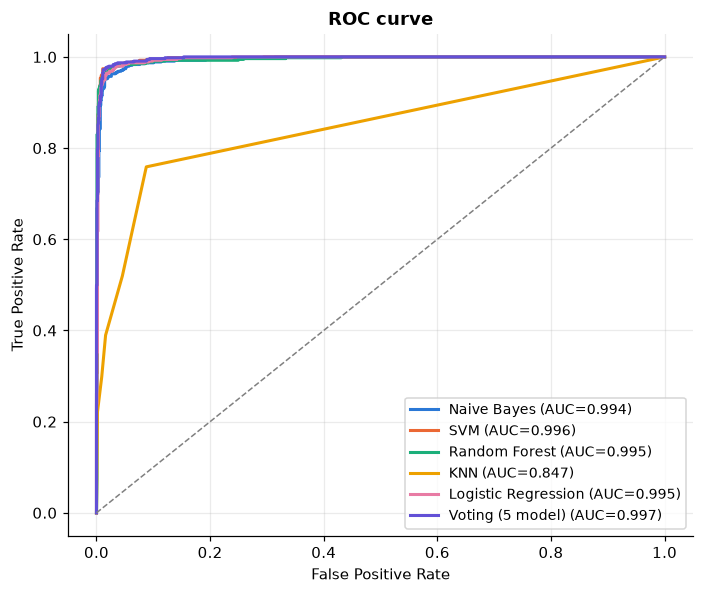

In [14]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for i, nama in enumerate(urutan):
    fpr, tpr, _ = roc_curve(y_test, prediksi[nama][1])
    ax.plot(fpr, tpr, color=WARNA_MODEL[i], lw=2, label=f"{nama} (AUC={hasil[nama]['ROC-AUC']:.3f})")
ax.plot([0, 1], [0, 1], ls="--", color="gray", lw=1)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC curve")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

**False Positive** = komentar normal yang dituduh promosi judi (mengganggu pengguna asli).
**False Negative** = promosi judi yang lolos.

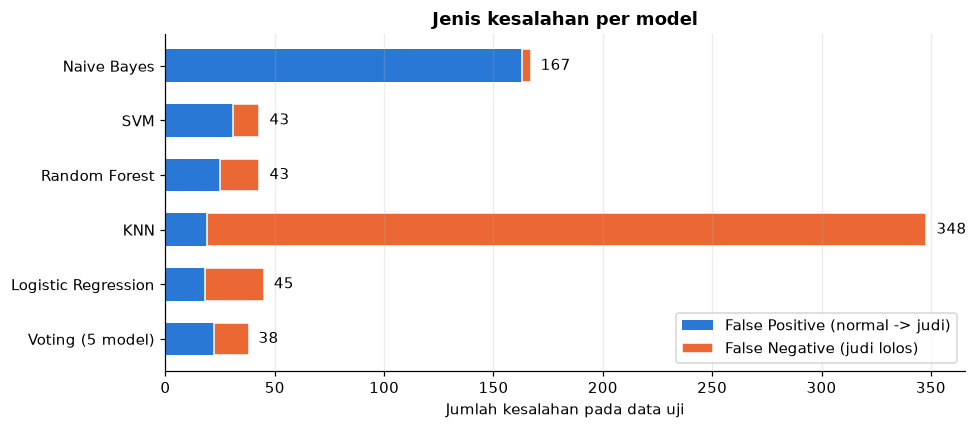

,TN,FP,FN,TP,Total salah
Naive Bayes,1023,163,4,535,167
SVM,1155,31,12,527,43
Random Forest,1161,25,18,521,43
KNN,1167,19,329,210,348
Logistic Regression,1168,18,27,512,45
Voting (5 model),1164,22,16,523,38


In [15]:
fpfn = pd.DataFrame({
    nama: dict(zip(["TN", "FP", "FN", "TP"], confusion_matrix(y_test, prediksi[nama][0]).ravel()))
    for nama in urutan}).T
fpfn["Total salah"] = fpfn["FP"] + fpfn["FN"]

fig, ax = plt.subplots(figsize=(9, 4))
y = np.arange(len(fpfn))
ax.barh(y, fpfn["FP"], color=WARNA_LABEL[0], height=0.6, label="False Positive (normal -> judi)")
ax.barh(y, fpfn["FN"], left=fpfn["FP"], color=WARNA_LABEL[1], height=0.6, label="False Negative (judi lolos)",
        edgecolor="white", linewidth=1)
for yi, total in zip(y, fpfn["Total salah"]):
    ax.text(total, yi, f"  {total}", va="center")
ax.set_yticks(y, fpfn.index)
ax.invert_yaxis()
ax.set_xlabel("Jumlah kesalahan pada data uji")
ax.set_title("Jenis kesalahan per model")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
fpfn

## 6. Analisis kesalahan & interpretasi

In [16]:
terbaik = metrics_df.drop(index="Voting (5 model)").index[0]
print("Model tunggal terbaik (F1):", terbaik)

salah = pd.DataFrame({"text_clean": X_test, "aktual": y_test,
                      "prediksi": prediksi[terbaik][0], "prob_judi": prediksi[terbaik][1]})
salah = salah[salah["aktual"] != salah["prediksi"]].sort_values("prob_judi")
print(f"Jumlah salah: {len(salah)}")
salah

Model tunggal terbaik (F1): SVM
Jumlah salah: 43


,text_clean,aktual,prediksi,prob_judi
1486,betul88 m4x w1n 25 25,1,0,0.009649
2977,ggwp88 tempatnya sloter sejati,1,0,0.041620
1824,coba dengerin orang ngegas,1,0,0.046609
8417,ya allah semoga komentar promosi dora77 panggil mu secepat amin,1,0,0.075344
6712,rasakan keseruan hadiah ggwp88,1,0,0.100116
637,akari awetnya terbaik,1,0,0.102015
1474,best coach sih,1,0,0.157353
3049,gile nyoba doang dapet cuan segede,1,0,0.200810
7473,suka strada old,1,0,0.206525
1408,berhenti ngehalu,1,0,0.226441


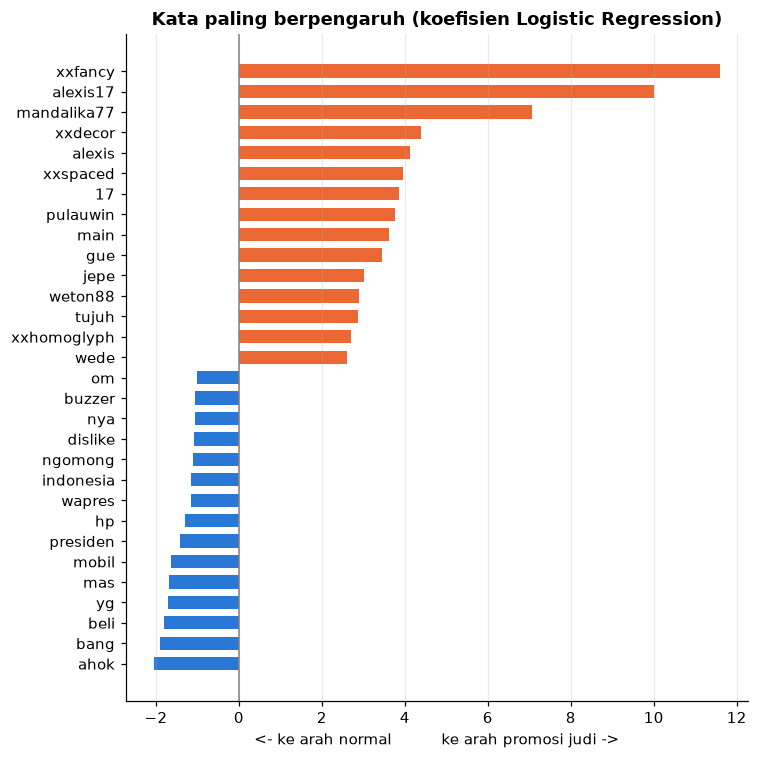

In [17]:
# Logistic Regression: koefisien positif -> mendorong ke "judi", negatif -> ke "normal"
lr = fitted["Logistic Regression"]
kata = lr.named_steps["tfidf"].get_feature_names_out()
coef = lr.named_steps["clf"].coef_[0]
idx = np.argsort(coef)
top = pd.concat([pd.Series(coef[idx[:15]], kata[idx[:15]]), pd.Series(coef[idx[-15:]], kata[idx[-15:]])])

fig, ax = plt.subplots(figsize=(7, 7))
ax.barh(top.index, top.values, color=[WARNA_LABEL[int(v > 0)] for v in top.values], height=0.65)
ax.axvline(0, color="gray", lw=1)
ax.set_title("Kata paling berpengaruh (koefisien Logistic Regression)")
ax.set_xlabel("<- ke arah normal          ke arah promosi judi ->")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### Uji coba kalimat baru

Termasuk trik huruf fancy/dispasi dan **nama situs yang tidak ada di dataset** (`zeus123`) untuk melihat keterbatasan model.
Huruf fancy ditulis dengan escape `\U...` agar sel ini tetap aman disalin.

In [18]:
kalimat = [
    "videonya keren banget bang, lanjutkan",
    "mobilnya bagus, kapan review yang versi listrik?",
    "auto jepe main di pluto88 modal receh",
    "\U0001d407\U0001d40e\U0001d40a\U0001d408 terus di \U0001d40f\U0001d40b\U0001d414\U0001d413\U0001d40e\U0001d7d6\U0001d7d6",  # HOKI ... PLUTO88 (huruf bold)
    "gas main di A L E X I S 1 7 pasti wd",
    "berkat zeus123 rezeki ngalir terus",
]
uji = pd.DataFrame({"kalimat": kalimat, "setelah_clean": [clean_text(k) for k in kalimat]})
for nama, m in fitted.items():
    uji[nama] = m.predict(uji["setelah_clean"])
uji["Voting"] = (uji[list(fitted)].mean(axis=1) >= 0.5).astype(int)
uji

,kalimat,setelah_clean,Naive Bayes,SVM,Random Forest,KNN,Logistic Regression,Voting
0,"videonya keren banget bang, lanjutkan",videonya keren banget bang lanjutkan,0,0,0,0,0,0
1,"mobilnya bagus, kapan review yang versi listrik?",mobilnya bagus review versi listrik,0,0,0,0,0,0
2,auto jepe main di pluto88 modal receh,auto jepe main pluto88 modal receh,1,1,1,0,1,1
3,𝐇𝐎𝐊𝐈 terus di 𝐏𝐋𝐔𝐓𝐎𝟖𝟖,hoki pluto88 xxfancy,1,1,1,0,1,1
4,gas main di A L E X I S 1 7 pasti wd,gas main alexis17 wd xxspaced,1,1,1,0,1,1
5,berkat zeus123 rezeki ngalir terus,berkat zeus123 rezeki ngalir,1,1,1,0,1,1


## 7. Eksperimen: seberapa bersih teks sebaiknya?

Promosi judi sering memakai karakter non-ASCII untuk menyamarkan kata kunci. Membersihkan terlalu agresif menghilangkan sinyal itu,
tetapi tidak membersihkan sama sekali membuat `PLUTO88` versi huruf bold menjadi token yang berbeda dari `pluto88`.
Empat pendekatan dibandingkan (semua memakai Logistic Regression agar adil dan cepat):

| Varian | Input | Fitur |
|---|---|---|
| A. Kata, tanpa sinyal | `clean_text(add_signals=False)` | TF-IDF kata |
| B. Kata + token sinyal (**default**) | `clean_text()` | TF-IDF kata (termasuk `xxfancy`, dst.) |
| C. Karakter, cleaning minimal | huruf kecil saja, **semua non-ASCII dibiarkan** | TF-IDF karakter 2-5 gram |
| D. Gabungan B + C | keduanya | TF-IDF kata + karakter |

Selain data uji biasa, komentar promosi di data uji juga **disamarkan secara sintetis** untuk menguji ketahanan:
- **bold**: semua huruf/angka diganti huruf Mathematical Bold
- **homoglif**: huruf a, e, o, p, c, x diganti huruf Cyrillic yang mirip
- **spasi**: nama situs (`alexis17`) ditulis `a l e x i s 1 7`

In [19]:
def light_clean(text):
    # Cleaning minimal: hanya huruf kecil, URL, mention, dan spasi. Non-ASCII DIBIARKAN.
    text = RE_URL.sub(" ", str(text).lower())
    text = RE_MENTION_HASHTAG.sub(" ", text)
    return re.sub(r"\s+", " ", text).strip()

BOLD = {**{chr(ord("A") + i): chr(0x1D400 + i) for i in range(26)},
        **{chr(ord("a") + i): chr(0x1D41A + i) for i in range(26)},
        **{chr(ord("0") + i): chr(0x1D7CE + i) for i in range(10)}}
CYRILLIC = {"a": "\u0430", "e": "\u0435", "o": "\u043e", "p": "\u0440", "c": "\u0441", "x": "\u0445"}
RE_BRAND = re.compile(r"\b[A-Za-z]+\d{2,}\b")

def samarkan(text, cara):
    if cara == "bold":
        return text.translate(str.maketrans(BOLD))
    if cara == "homoglif":
        return text.translate(str.maketrans(CYRILLIC))
    if cara == "spasi":
        return RE_BRAND.sub(lambda m: " ".join(m.group()), text)
    return text

contoh_brand = "gas main di alexis17 pasti jp"
for cara in ["bold", "homoglif", "spasi"]:
    t = samarkan(contoh_brand, cara)
    print(f"{cara:9s} {t!r:45s} -> {clean_text(t)!r}")

bold      '𝐠𝐚𝐬 𝐦𝐚𝐢𝐧 𝐝𝐢 𝐚𝐥𝐞𝐱𝐢𝐬𝟏𝟕 𝐩𝐚𝐬𝐭𝐢 𝐣𝐩'               -> 'gas main alexis17 jp xxfancy'
homoglif  'gаs mаin di аlехis17 раsti jр'               -> 'gas main alexis17 jp xxhomoglyph'
spasi     'gas main di a l e x i s 1 7 pasti jp'        -> 'gas main alexis17 jp xxspaced'


In [20]:
def kolom(idx):
    d = data.loc[idx, ["text_clean", "text_plain", "komentar"]].copy()
    d["text_min"] = d["komentar"].apply(light_clean)
    return d

D_train, D_test = kolom(X_train.index), kolom(X_test.index)

def char_tfidf():
    return TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), max_features=50000, sublinear_tf=True)

def lr():
    return LogisticRegression(max_iter=2000)

VARIAN = {
    "A. Kata, tanpa sinyal": Pipeline([("fitur", ColumnTransformer([("w", tfidf(), "text_plain")])), ("clf", lr())]),
    "B. Kata + sinyal (default)": Pipeline([("fitur", ColumnTransformer([("w", tfidf(), "text_clean")])), ("clf", lr())]),
    "C. Karakter, cleaning minimal": Pipeline([("fitur", ColumnTransformer([("c", char_tfidf(), "text_min")])), ("clf", lr())]),
    "D. Gabungan B + C": Pipeline([("fitur", ColumnTransformer([("w", tfidf(), "text_clean"), ("c", char_tfidf(), "text_min")])),
                                   ("clf", lr())]),
}

# Komentar promosi di data uji yang disamarkan secara sintetis
promo_test = D_test.loc[y_test[y_test == 1].index, "komentar"]
uji_samaran = {}
for cara in ["bold", "homoglif", "spasi"]:
    raw = promo_test.apply(samarkan, cara=cara)
    if cara == "spasi":
        raw = raw[promo_test.str.contains(RE_BRAND)]  # hanya komentar yang memang memuat nama situs
    uji_samaran[cara] = pd.DataFrame({"komentar": raw, "text_clean": raw.apply(clean_text),
                                      "text_plain": raw.apply(clean_text, add_signals=False),
                                      "text_min": raw.apply(light_clean)})

eksperimen = {}
for nama, pipe in VARIAN.items():
    pipe.fit(D_train, y_train)
    pred = pipe.predict(D_test)
    baris = {"F1 (uji biasa)": f1_score(y_test, pred),
             "False positive": int(((pred == 1) & (y_test == 0)).sum())}
    for cara, d in uji_samaran.items():
        baris[f"Recall samaran {cara}"] = pipe.predict(d).mean()
    eksperimen[nama] = baris

eksperimen_df = pd.DataFrame(eksperimen).T
eksperimen_df["False positive"] = eksperimen_df["False positive"].astype(int)
print({cara: len(d) for cara, d in uji_samaran.items()}, "komentar promosi per jenis samaran")
eksperimen_df.style.format("{:.3f}").format("{:d}", subset=["False positive"]).background_gradient(
    cmap="Blues", subset=[c for c in eksperimen_df.columns if c != "False positive"])

{'bold': 539, 'homoglif': 539, 'spasi': 138} komentar promosi per jenis samaran


,F1 (uji biasa),False positive,Recall samaran bold,Recall samaran homoglif,Recall samaran spasi
"A. Kata, tanpa sinyal",0.952,27,0.954,0.954,0.964
B. Kata + sinyal (default),0.958,18,0.998,0.991,0.978
"C. Karakter, cleaning minimal",0.964,12,0.625,0.868,0.942
D. Gabungan B + C,0.978,10,0.996,0.981,0.986


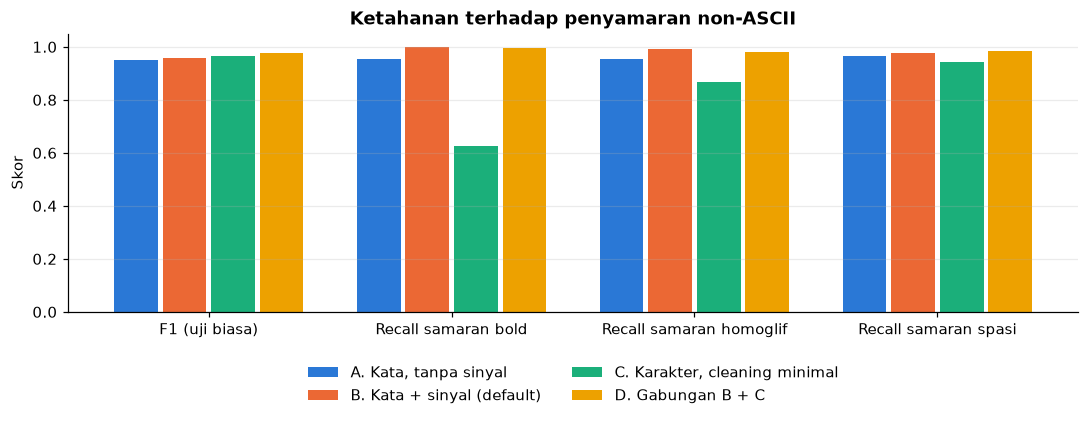

In [21]:
kolom_plot = [c for c in eksperimen_df.columns if c != "False positive"]
fig, ax = plt.subplots(figsize=(10, 4.2))
lebar = 0.8 / len(eksperimen_df)
for i, nama in enumerate(eksperimen_df.index):
    x = np.arange(len(kolom_plot)) + i * lebar - 0.4 + lebar / 2
    ax.bar(x, eksperimen_df.loc[nama, kolom_plot], width=lebar * 0.9, color=WARNA_MODEL[i], label=nama)
ax.set_xticks(np.arange(len(kolom_plot)), kolom_plot)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Skor")
ax.set_title("Ketahanan terhadap penyamaran non-ASCII")
ax.legend(ncol=2, loc="lower center", bbox_to_anchor=(0.5, -0.38), frameon=False)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

In [22]:
# Bobot token sinyal pada varian B: positif = mendorong ke "promosi judi"
b = VARIAN["B. Kata + sinyal (default)"]
fitur_b = b.named_steps["fitur"].get_feature_names_out()
coef_b = pd.Series(b.named_steps["clf"].coef_[0], index=[f.split("__", 1)[1] for f in fitur_b])
print("Koefisien token sinyal (Logistic Regression, varian B):")
print(coef_b.reindex(list(SINYAL)).round(3).to_string())
print()
print("Proporsi data latih yang memuat token sinyal:")
for k in SINYAL:
    print(f"  {k:12s} judi {D_train.loc[y_train == 1, 'text_clean'].str.contains(k).mean():6.1%}"
          f" | normal {D_train.loc[y_train == 0, 'text_clean'].str.contains(k).mean():6.1%}")

Koefisien token sinyal (Logistic Regression, varian B):
xxfancy        11.591
xxhomoglyph     2.699
xxspaced        3.952
xxdecor         4.385

Proporsi data latih yang memuat token sinyal:
  xxfancy      judi  50.0% | normal   0.9%
  xxhomoglyph  judi   5.5% | normal   0.0%
  xxspaced     judi   8.5% | normal   0.0%
  xxdecor      judi   9.5% | normal   0.5%


### Kesimpulan eksperimen

Hasil saat notebook ini diuji (angka bisa sedikit berbeda antar versi library):

| Varian | F1 uji biasa | False positive | Recall samaran bold | homoglif | spasi |
|---|---|---|---|---|---|
| A. Kata, tanpa sinyal | 0.952 | 27 | 0.954 | 0.954 | 0.964 |
| B. Kata + sinyal (default) | 0.958 | 18 | **0.998** | **0.991** | 0.978 |
| C. Karakter, cleaning minimal | 0.964 | 12 | 0.625 | 0.868 | 0.942 |
| D. Gabungan B + C | **0.978** | **10** | 0.996 | 0.981 | **0.986** |

1. **Membiarkan non-ASCII apa adanya (C) rapuh.** Skor di data uji biasa bagus, tetapi begitu spammer mengganti gaya huruf
   (bold), recall jatuh ke ~0.63 - n-gram karakter `𝐩𝐥𝐮𝐭𝐨` tidak mirip sama sekali dengan `pluto`.
2. **Normalisasi saja (A) tahan penyamaran tetapi kehilangan informasi** bahwa komentar itu disamarkan -> false positive paling banyak.
3. **Normalisasi + token sinyal (B)** mendapat keduanya: kata kuncinya terbaca *dan* triknya menjadi bukti tambahan
   (`xxfancy` muncul di ~50% komentar judi vs <1% komentar normal; koefisiennya paling besar).
4. **Gabungan (D)** paling baik secara keseluruhan. Untuk implementasi ulang, D layak dijadikan model utama.

**Prinsipnya: jangan buang non-ASCII, tapi juga jangan dipakai mentah - terjemahkan menjadi (a) teks yang terbaca dan (b) fitur penanda penyamaran.**

Trik yang belum tertangani dan bisa jadi pengembangan: *leetspeak* (`m4x w1n` = maxwin, terlihat di analisis kesalahan),
nama situs baru yang belum ada di data latih, serta emoji yang dipakai sebagai huruf.

## 8. Simpan model & informasi training

In [23]:
os.makedirs(OUTPUT_DIR, exist_ok=True)
for nama, model in fitted.items():
    joblib.dump(model, os.path.join(OUTPUT_DIR, f"{nama.replace(' ', '_').lower()}.joblib"))

# Model eksperimen terbaik (varian D). Inputnya DataFrame berkolom text_clean & text_min (lihat notebook 01).
joblib.dump(VARIAN["D. Gabungan B + C"], os.path.join(OUTPUT_DIR, "gabungan_kata_karakter.joblib"))

metrics_df.to_csv(os.path.join(OUTPUT_DIR, "metrics.csv"))
eksperimen_df.to_csv(os.path.join(OUTPUT_DIR, "eksperimen_cleaning.csv"))

info = {
    "dibuat": datetime.now().isoformat(timespec="seconds"),
    "dataset": "kaggle: yaemico/judionline",
    "kolom_teks": "komentar -> clean_text()",
    "catatan_penting": "Pipeline menerima teks yang SUDAH dibersihkan dengan clean_text() yang sama.",
    "jumlah_data": {
        "awal": int(n_awal),
        "setelah_dedup": int(len(data)),
        "train_sebelum_balancing": int(len(X_train_full)),
        "train_setelah_balancing": int(len(X_train)),
        "test": int(len(X_test)),
        "test_distribusi_label": {int(k): int(v) for k, v in y_test.value_counts().items()},
    },
    "vectorizer": {"jenis": "TfidfVectorizer", "max_features": 5000},
    "parameter_model": {n: {k: str(v) for k, v in m.named_steps["clf"].get_params().items()} for n, m in fitted.items()},
    "metrik_uji": {n: {k: (None if pd.isna(v) else round(float(v), 4)) for k, v in h.items()} for n, h in hasil.items()},
    "model_terbaik_f1": terbaik,
    "voting": "prediksi 1 jika >= 3 dari 5 model memprediksi 1",
    "token_sinyal": SINYAL,
    "eksperimen_cleaning": {n: {k: round(float(v), 4) for k, v in r.items()} for n, r in eksperimen_df.iterrows()},
    "model_gabungan": "gabungan_kata_karakter.joblib - input DataFrame(text_clean=clean_text(x), text_min=light_clean(x))",
    "versi": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
              "pandas": pd.__version__, "numpy": np.__version__},
}
with open(os.path.join(OUTPUT_DIR, "training_info.json"), "w") as f:
    json.dump(info, f, indent=2, ensure_ascii=False)

shutil.make_archive("models", "zip", OUTPUT_DIR)
for f in sorted(os.listdir(OUTPUT_DIR)):
    print(f"{f:35s} {os.path.getsize(os.path.join(OUTPUT_DIR, f)) / 1024:8.1f} KB")
print("\nArsip: models.zip")

eksperimen_cleaning.csv                  0.5 KB
gabungan_kata_karakter.joblib         2338.3 KB
knn.joblib                             512.4 KB
logistic_regression.joblib             216.9 KB
metrics.csv                              1.0 KB
naive_bayes.joblib                     334.0 KB
random_forest.joblib                  8405.2 KB
svm.joblib                             454.4 KB
training_info.json                       5.6 KB

Arsip: models.zip


In [24]:
# Cek: model yang disimpan bisa dimuat ulang dan hasilnya sama
m = joblib.load(os.path.join(OUTPUT_DIR, "svm.joblib"))
assert (m.predict(X_test) == prediksi["SVM"][0]).all()
print("OK - model berhasil dimuat ulang")

OK - model berhasil dimuat ulang


In [25]:
# Di Google Colab: unduh models.zip untuk dipakai di notebook 01 (bagian prediksi)
try:
    from google.colab import files
    files.download("models.zip")
except ImportError:
    print("Bukan di Colab - models.zip ada di folder kerja:", os.path.abspath("models.zip"))

Bukan di Colab - models.zip ada di folder kerja: /home/drpoch/Devapp/claude/Tesis/tugas/NLP-AdvanceAI/Online-Gamblig-Skripsie/notebooks/models.zip


## Catatan

- Skor sangat tinggi karena promosi judi di dataset ini didominasi **nama situs** (`alexis17`, `sgi88`, ...) dan kalimat template.
  Lihat hasil kalimat `zeus123` di atas: nama situs baru yang tidak ada di data latih lebih sulit dikenali.
- Ide pengembangan: TF-IDF karakter n-gram (lebih tahan variasi ejaan), fitur pola `huruf+angka`, atau model transformer (IndoBERT).
- Model disimpan sebagai `Pipeline` sehingga cukup: `model.predict([clean_text(teks)])`.